In [ ]:
import pandas
import seaborn
from matplotlib import pyplot
from pandas.plotting import register_matplotlib_converters

from airpollutionforecasting.pipeline import run_pipeline
from airpollutionforecasting.eda.ts_correlation import TSCorrelationChecker

register_matplotlib_converters()
seaborn.set_style("darkgrid")

2026-11-18 20:17:08.818 | INFO     | airpollutionforecasting.config:<module>:18 - PROJ_ROOT path is: /home/pabito/Desktop/Projects/AirPolutionForecasting


In [2]:
pyplot.rc("figure", figsize=(16, 12))
pyplot.rc("font", size=13)

In [3]:
# run the pipeline to get the location of splitted files
split_files_locations = run_pipeline(stop_step="split")
# load the training data
data = pandas.read_csv(split_files_locations[0])
data["time"] = pandas.to_datetime(data["time"])

2026-11-18 20:18:27.991 | INFO     | airpollutionforecasting.pipeline:run_pipeline:28 - Running pipeline until split...
2026-11-18 20:18:27.993 | INFO     | airpollutionforecasting.data.loader:load:20 - Loading the data..
2026-11-18 20:18:28.091 | INFO     | airpollutionforecasting.data.data_validator:validate:149 - Starting data validation...
2026-11-18 20:18:28.091 | INFO     | airpollutionforecasting.data.data_validator:validate:151 - Checking required columns and data types...
2026-11-18 20:18:28.092 | SUCCESS  | airpollutionforecasting.data.data_validator:validate:153 - Column and data type validation passed.
2026-11-18 20:18:28.092 | INFO     | airpollutionforecasting.data.data_validator:validate:155 - Checking configured date range...
2026-11-18 20:18:28.093 | SUCCESS  | airpollutionforecasting.data.data_validator:validate:157 - Date range validation passed.
2026-11-18 20:18:28.093 | INFO     | airpollutionforecasting.data.data_validator:validate:159 - Checking for missing value

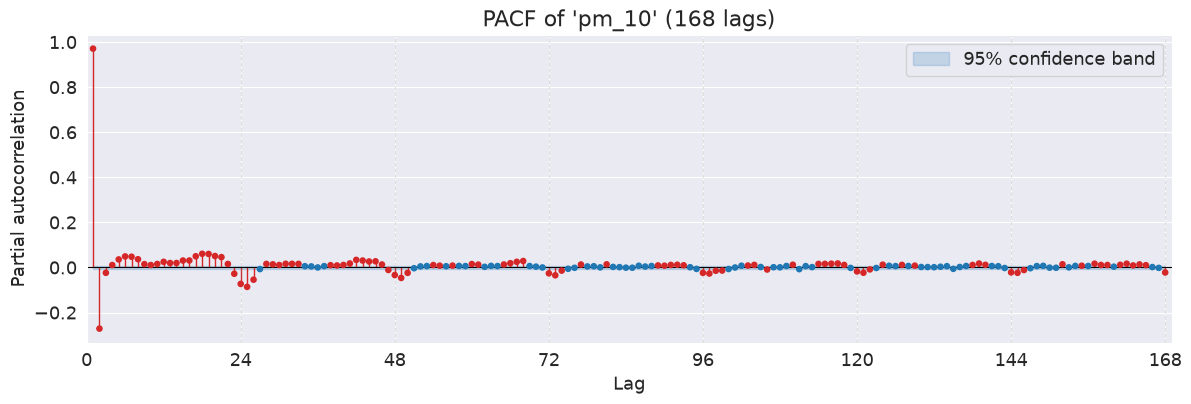

In [ ]:
checker = TSCorrelationChecker(data, target_col="pm_10")

checker.plot_pacf_graph(
    nlags=168, seasonal_period=24
)  # daily guide lines every 24 lags
pyplot.show()

In [6]:
pacf_df = checker.calculate_pacf(nlags=168)

# Significant lags, strongest first
pacf_df[pacf_df["significant"]].sort_values("pacf", key=abs, ascending=False).head(10)

,pacf,lower,upper,significant
lag,,,,
1,0.971045,-0.007667,0.007667,True
2,-0.271400,-0.007667,0.007667,True
25,-0.086156,-0.007667,0.007667,True
24,-0.072964,-0.007667,0.007667,True
18,0.060560,-0.007667,0.007667,True
19,0.059914,-0.007667,0.007667,True
26,-0.054312,-0.007667,0.007667,True
20,0.050683,-0.007667,0.007667,True
17,0.049596,-0.007667,0.007667,True
